**Notebook Criado por:** MSc. Eng. Paulo Silva  
**Notebook Criado em:** 12 / 11 / 2026  
**Última Atualização:** 17 / 11 / 2026  

**Obs:** Este notebook foi desenvolvido sob auxílio de ferramentas de IA.

# **Aula 08 — Problema 1D direto com geração de calor**

## Comparação entre uma **implementação dimensional** e uma **implementação normalizada**

Neste notebook resolvemos o mesmo problema de condução estacionária em uma parede plana, com geração uniforme de energia, usando uma PINN no DeepXDE.

Serão apresentadas duas implementações:

1. **tentativa inicial:** a rede trabalha com a temperatura de excesso em Kelvin, ***sem uma escala adimensional***;
2. **implementação normalizada:** a rede trabalha com coordenada e temperatura adimensionais.

A primeira versão permite visualizar erros muito comuns em problemas simples: misturar temperatura absoluta com temperatura relativa e treinar a rede com grandezas de escalas muito diferentes.

> A solução analítica é usada para:  
> * Gerar dados sintéticos e para avaliar a resposta.   
> * Ela não é utilizada como parte da física no treinamento sem dados.

## **1. Formulação física**

> **Obs.:** Note que a formulação da solução aqui é ligeiramente diferente da apresentada em notebooks anteriores.

Consideramos uma parede plana de comprimento $L$, com geração volumétrica uniforme $\dot q$, condutividade térmica $k$ constante e as duas superfícies mantidas na temperatura $T_s$.

Como o problema é estacionário e unidimensional,

$$
k\frac{d^2T}{dx^2}+\dot q=0,
\qquad 0<x<L.
$$

Com

$$
T(0)=T(L)=T_s,
$$

a solução analítica é

$$
T(x)=T_s+\frac{\dot q}{2k}x(L-x).
$$

O parâmetro que aparece diretamente na equação é

$$
C=\frac{\dot q}{k}.
$$

Portanto, se $k$ aumenta mantendo $\dot q$ fixo, a variação de temperatura diminui. Isso é fisicamente esperado: materiais mais condutores apresentam menor gradiente de temperatura para a mesma geração interna.

## **2. Ambiente e parâmetros**

Os valores abaixo produzem uma solução simples de visualizar. O valor de $k$ pode ser aumentado na célula para testar a sensibilidade da implementação dimensional.

Neste exemplo, a rede não recebe $T$ diretamente. Na primeira implementação, ela aproxima a **temperatura de excesso**

$$
u(x)=T(x)-T_s.
$$

Na segunda implementação, essa temperatura de excesso ainda será dividida por uma escala característica, produzindo uma variável da ordem de $1$.

In [1]:
# Se necessário no Google Colab, descomente:
# !pip -q install deepxde torch
!pip -q install deepxde torch

In [2]:
import os

# O backend deve ser definido antes da importação do DeepXDE.
os.environ["DDE_BACKEND"] = "pytorch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import deepxde as dde
import matplotlib.pyplot as plt
import numpy as np

dde.config.set_default_float("float64")
dde.config.set_random_seed(1234)

print("Backend utilizado:", dde.backend.backend_name)

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


Set the default float type to float64
Backend utilizado: pytorch


In [3]:
# Propriedades e condições físicas
L = 1.0          # comprimento da parede [m]
Ts = 500.0       # temperatura das superfícies [K]
q_dot = 15000.0  # geração volumétrica [W/m³]
k = 150.0        # condutividade térmica [W/(m K)]

# Parâmetro equivalente da equação
C_REF = q_dot / k

# Configuração didática do treinamento
ITERATIONS = 500
NUM_DOMAIN = 200
NUM_BOUNDARY = 40
NUM_TEST = 400

print(f"C = q_dot/k = {C_REF:.6g} K/m²")
print(f"Temperatura de excesso máxima esperada = {C_REF * L**2 / 8:.6g} K")

C = q_dot/k = 100 K/m²
Temperatura de excesso máxima esperada = 12.5 K


## **3. Solução analítica e dados de referência**

A solução analítica será calculada em uma malha de avaliação. Também serão criadas observações internas sintéticas para o experimento com dados.

In [4]:
def temperatura_analitica(x):
    """Temperatura dimensional em Kelvin."""
    x = np.asarray(x)
    return Ts + 0.5 * C_REF * x * (L - x)


def excesso_analitico(x):
    """Temperatura de excesso u = T - Ts, em Kelvin."""
    return temperatura_analitica(x) - Ts


x_eval = np.linspace(0.0, L, 401).reshape(-1, 1)
T_ref = temperatura_analitica(x_eval)
u_ref = excesso_analitico(x_eval)

indice_maximo = np.argmax(T_ref[:, 0])
x_maximo = x_eval[indice_maximo, 0]
T_maximo = T_ref[indice_maximo, 0]

print(f"Temperatura máxima analítica: {T_maximo:.3f} K")
print(f"Posição da temperatura máxima: x = {x_maximo:.3f} m")

Temperatura máxima analítica: 512.500 K
Posição da temperatura máxima: x = 0.500 m


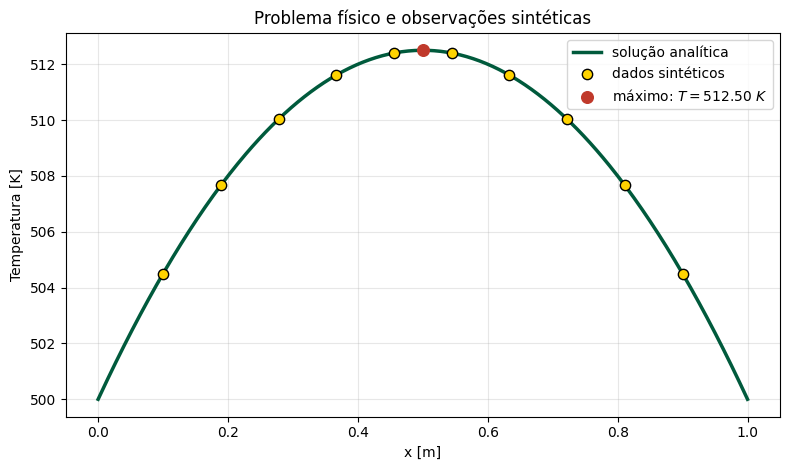

In [5]:
x_obs = np.linspace(0.1 * L, 0.9 * L, 10).reshape(-1, 1)

# Dados em temperatura absoluta e em temperatura de excesso.
T_obs = temperatura_analitica(x_obs)
u_obs = T_obs - Ts

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(x_eval[:, 0], T_ref[:, 0], color="#005A3C", linewidth=2.5,
        label="solução analítica")
ax.scatter(x_obs[:, 0], T_obs[:, 0], color="#FFD300", edgecolor="black",
           s=55, zorder=3, label="dados sintéticos")
ax.scatter([x_maximo], [T_maximo], color="#C0392B", s=70, zorder=4,
           label=fr"máximo: $T={T_maximo:.2f}\ K$")
ax.set_title("Problema físico e observações sintéticas")
ax.set_xlabel("x [m]")
ax.set_ylabel("Temperatura [K]")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## **4. Implementação inicial: temperatura de excesso em Kelvin**

Para evitar carregar o valor de $500\,\mathrm{K}$ durante o treinamento, a primeira tentativa aproxima

$$
u(x)=T(x)-T_s.
$$

A equação e as condições são

$$
\frac{d^2u}{dx^2}+C=0,
\qquad
u(0)=u(L)=0.
$$

Essa formulação é fisicamente equivalente à formulação em $T$, mas ainda não é uma normalização completa: $u$ continua sendo medido em Kelvin e pode ter valores muito pequenos ou muito grandes dependendo de $k$, $\dot q$ e $L$.

In [6]:
geom_raw = dde.geometry.Interval(0.0, L)        # Definicao da geometria

# Definicao da PDE
def pde_raw(x, y):
    d2u_dx2 = dde.grad.hessian(y, x, i=0, j=0)
    return d2u_dx2 + C_REF

# Definicao da posicao do contorno
def boundary_raw(x, on_boundary):
    return on_boundary

# Definicao do valor no contorno
def excesso_nulo(x):
    return np.zeros((len(x), 1))

# Definindo o BC para a biblioteca
bc_raw = dde.icbc.DirichletBC(
    geom_raw,
    excesso_nulo,
    boundary_raw,
)

In [7]:
def criar_modelo_raw(usando_dados, seed=1234):
    dde.config.set_random_seed(seed)

    bcs = [bc_raw]

    if usando_dados:
        bcs.append(dde.icbc.PointSetBC(x_obs, u_obs, component=0,))

    data = dde.data.PDE(
        geom_raw,
        pde_raw,
        bcs,
        num_domain=NUM_DOMAIN,
        num_boundary=NUM_BOUNDARY,
        num_test=NUM_TEST,
    )

    net = dde.nn.FNN(
        [1] + [32] * 3 + [1],
        "tanh",
        "Glorot uniform",
    )

    model = dde.Model(data, net)
    model.compile("adam", lr=1e-3)
    return model

def treinar_raw(usando_dados, seed=1234):
    nome = "com dados" if usando_dados else "sem dados"
    print(f"\nTreinamento dimensional — {nome}")

    model = criar_modelo_raw(usando_dados, seed=seed)
    inicio = time.perf_counter()
    losshistory, train_state = model.train(
        iterations=ITERATIONS,
        display_every=100,
        verbose=1,
    )
    tempo = time.perf_counter() - inicio

    return {
        "modelo": model,
        "losshistory": losshistory,
        "train_state": train_state,
        "tempo": tempo,
    }


resultados_raw = {
    "sem dados": treinar_raw(False, seed=1234),
    "com dados": treinar_raw(True, seed=1234),
}


Treinamento dimensional — sem dados
Compiling model...
'compile' took 6.170726 s

Training model...

Step      Train loss              Test loss               Test metric
0         [1.00e+04, 1.61e-03]    [1.00e+04, 1.61e-03]    []  


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


100       [5.25e+03, 4.03e+01]    [5.46e+03, 4.03e+01]    []  
200       [3.05e+03, 9.74e+01]    [2.97e+03, 9.74e+01]    []  
300       [1.80e+03, 2.00e+02]    [1.62e+03, 2.00e+02]    []  
400       [1.08e+03, 2.99e+02]    [9.54e+02, 2.99e+02]    []  
500       [6.50e+02, 3.83e+02]    [5.87e+02, 3.83e+02]    []  

Best model at step 500:
  train loss: 1.03e+03
  test loss: 9.70e+02
  test metric: []

'train' took 3.621777 s


Treinamento dimensional — com dados
Compiling model...
'compile' took 0.000167 s

Training model...

Step      Train loss                        Test loss                         Test metric
0         [1.00e+04, 1.61e-03, 9.30e+01]    [1.00e+04, 1.61e-03, 9.30e+01]    []  
100       [5.28e+03, 4.27e+01, 6.88e+00]    [5.50e+03, 4.27e+01, 6.88e+00]    []  
200       [3.07e+03, 9.68e+01, 2.21e+01]    [3.00e+03, 9.68e+01, 2.21e+01]    []  
300       [1.85e+03, 1.93e+02, 4.85e+01]    [1.66e+03, 1.93e+02, 4.85e+01]    []  
400       [1.09e+03, 2.91e+02, 7.42e+01]    [9.

### **4.1 O erro de comparação que apareceu na primeira tentativa**

A rede acima produz $u=T-T_s$, isto é, **temperatura de excesso**. Portanto, sua saída não pode ser comparada diretamente com $T$, que está em temperatura absoluta.

O gráfico abaixo reproduz o erro conceitual:

$$
\text{erro incorreto}=|T-u_{\mathrm{PINN}}|.
$$

O erro correto deve usar

$$
T_{\mathrm{PINN}}=T_s+u_{\mathrm{PINN}}.
$$

In [8]:
def avaliar_raw(resultado):
    u_pred = resultado["modelo"].predict(x_eval)

    # Comparação incorreta: mistura T absoluto com u de excesso.
    erro_incorreto = np.abs(T_ref - u_pred)

    # Comparação correta: recupera a temperatura absoluta.
    T_pred = Ts + u_pred
    erro_correto = np.abs(T_ref - T_pred)

    return {
        "u_pred": u_pred,
        "T_pred": T_pred,
        "erro_incorreto": erro_incorreto,
        "erro_abs": erro_correto,
    }


for nome, resultado in resultados_raw.items():
    resultado.update(avaliar_raw(resultado))

    print(f"\nCaso dimensional: {nome}")
    print(f"Erro incorreto máximo: {np.max(resultado['erro_incorreto']):.4e} K")
    print(f"Erro correto máximo:   {np.max(resultado['erro_abs']):.4e} K")


Caso dimensional: sem dados
Erro incorreto máximo: 5.1786e+02 K
Erro correto máximo:   2.1879e+01 K

Caso dimensional: com dados
Erro incorreto máximo: 5.1747e+02 K
Erro correto máximo:   2.1867e+01 K


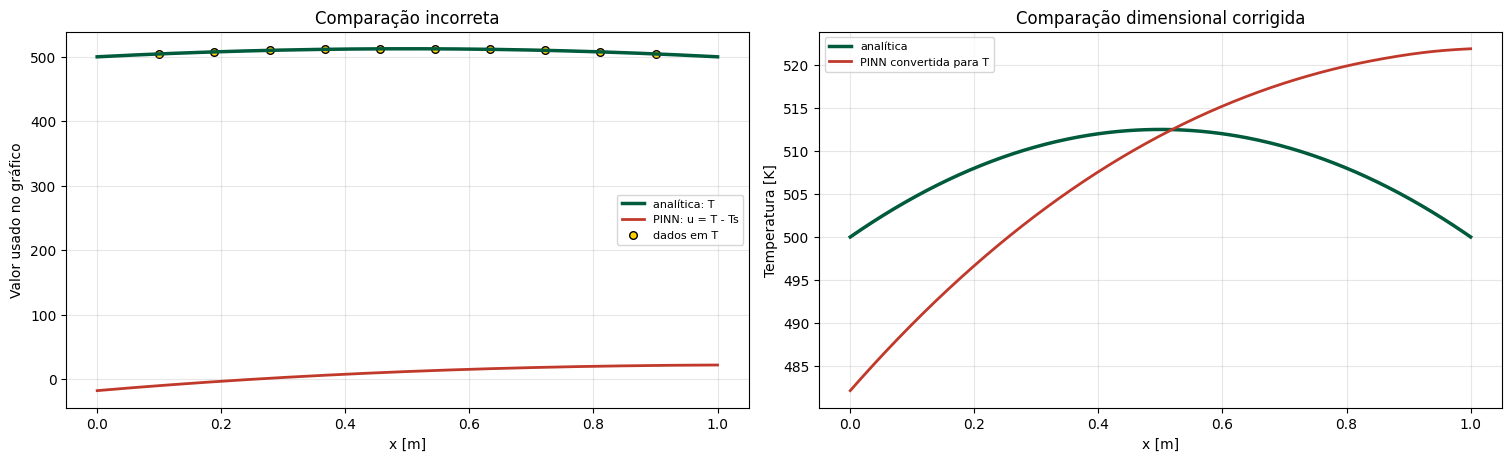

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)

axes[0].plot(x_eval[:, 0], T_ref[:, 0], color="#005A3C",
             linewidth=2.5, label="analítica: T")
axes[0].plot(x_eval[:, 0], resultados_raw["sem dados"]["u_pred"][:, 0],
             color="#C0392B", linewidth=2,
             label="PINN: u = T - Ts")
axes[0].scatter(x_obs[:, 0], T_obs[:, 0], color="#FFD300",
                edgecolor="black", s=30, label="dados em T")
axes[0].set_title("Comparação incorreta")
axes[0].set_ylabel("Valor usado no gráfico")
axes[0].legend(fontsize=8)

axes[1].plot(x_eval[:, 0], T_ref[:, 0], color="#005A3C",
             linewidth=2.5, label="analítica")
axes[1].plot(x_eval[:, 0], resultados_raw["sem dados"]["T_pred"][:, 0],
             color="#C0392B", linewidth=2,
             label="PINN convertida para T")
axes[1].set_title("Comparação dimensional corrigida")
axes[1].set_ylabel("Temperatura [K]")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.set_xlabel("x [m]")
    ax.grid(True, alpha=0.3)

plt.show()

## **5. Implementação normalizada**

Agora normalizamos espaço e temperatura:

$$\xi=\frac{x}{L}, \qquad \theta=\frac{T-T_s}{\Delta T},$$

com a escala característica

$$\Delta T=\frac{|\dot q|L^2}{k}.$$

Substituindo na equação, obtemos

$$
\frac{d^2\theta}{d\xi^2}+S=0, \qquad
S=\frac{\dot q L^2}{k\Delta T}.
$$

Para $\dot q>0$, $S=1$. A rede passa a trabalhar com valores de entrada e saída de ordem aproximadamente unitária. No final, recuperamos a temperatura física usando

$$
T=T_s+\Delta T\,\theta.
$$

In [10]:
# Escala de temperatura e fonte adimensionais
delta_T = abs(q_dot) * L**2 / k

if delta_T == 0:
    delta_T = 1.0

source_adim = q_dot * L**2 / (k * delta_T)

def theta_analitica(xi):
    """Solução analítica adimensional."""
    xi = np.asarray(xi)
    return 0.5 * source_adim * xi * (1.0 - xi)

def temperatura_a_partir_de_theta(theta):
    """Converte a saída adimensional para Kelvin."""
    return Ts + delta_T * theta

xi_eval = x_eval / L
theta_ref = theta_analitica(xi_eval)
T_ref_normalizada = temperatura_a_partir_de_theta(theta_ref)

xi_obs = x_obs / L
theta_obs = theta_analitica(xi_obs)

print(f"Escala ΔT = {delta_T:.6g} K")
print(f"Fonte adimensional S = {source_adim:.6g}")
print(f"theta máximo = {np.max(theta_ref):.6g}")

Escala ΔT = 100 K
Fonte adimensional S = 1
theta máximo = 0.125


In [11]:
geom_norm = dde.geometry.Interval(0.0, 1.0)

def pde_norm(x, y):
    d2theta_dxi2 = dde.grad.hessian(y, x, i=0, j=0)
    return d2theta_dxi2 + source_adim

def boundary_norm(x, on_boundary):
    return on_boundary

def theta_nula(x):
    return np.zeros((len(x), 1))

bc_norm = dde.icbc.DirichletBC(geom_norm, theta_nula, boundary_norm,)

def criar_modelo_norm(usando_dados, seed=1234):
    dde.config.set_random_seed(seed)
    bcs = [bc_norm]

    if usando_dados:
        bcs.append(dde.icbc.PointSetBC(
                xi_obs,
                theta_obs,
                component=0,
            )
        )

    data = dde.data.PDE(
        geom_norm,
        pde_norm,
        bcs,
        num_domain=NUM_DOMAIN,
        num_boundary=NUM_BOUNDARY,
        num_test=NUM_TEST,
    )

    net = dde.nn.FNN(
        [1] + [32] * 3 + [1],
        "tanh",
        "Glorot uniform",
    )

    model = dde.Model(data, net)
    model.compile("adam", lr=1e-3)
    return model


def treinar_norm(usando_dados, seed=1234):
    nome = "com dados" if usando_dados else "sem dados"
    print(f"\nTreinamento normalizado — {nome}")

    model = criar_modelo_norm(usando_dados, seed=seed)
    inicio = time.perf_counter()
    losshistory, train_state = model.train(
        iterations=ITERATIONS,
        display_every=100,
        verbose=1,
    )
    tempo = time.perf_counter() - inicio

    return {
        "modelo": model,
        "losshistory": losshistory,
        "train_state": train_state,
        "tempo": tempo,
    }


resultados_norm = {
    "sem dados": treinar_norm(False, seed=1234),
    "com dados": treinar_norm(True, seed=1234),
}


Treinamento normalizado — sem dados
Compiling model...
'compile' took 0.000154 s

Training model...

Step      Train loss              Test loss               Test metric
0         [9.86e-01, 1.61e-03]    [9.85e-01, 1.61e-03]    []  
100       [3.19e-02, 1.16e-03]    [2.32e-02, 1.16e-03]    []  
200       [8.93e-03, 4.17e-05]    [6.45e-03, 4.17e-05]    []  
300       [3.50e-03, 4.73e-06]    [2.54e-03, 4.73e-06]    []  
400       [1.40e-03, 6.73e-07]    [1.01e-03, 6.73e-07]    []  
500       [3.88e-04, 8.98e-08]    [2.67e-04, 8.98e-08]    []  

Best model at step 500:
  train loss: 3.88e-04
  test loss: 2.67e-04
  test metric: []

'train' took 3.154114 s


Treinamento normalizado — com dados
Compiling model...
'compile' took 0.000140 s

Training model...

Step      Train loss                        Test loss                         Test metric
0         [9.86e-01, 1.61e-03, 4.66e-03]    [9.85e-01, 1.61e-03, 4.66e-03]    []  
100       [3.22e-02, 6.29e-04, 1.67e-04]    [2.33e-02, 6.29e-

In [12]:
def avaliar_norm(resultado):
    theta_pred = resultado["modelo"].predict(xi_eval)
    T_pred = temperatura_a_partir_de_theta(theta_pred)
    erro_abs = np.abs(T_ref_normalizada - T_pred)

    loss_train = np.asarray(
        resultado["losshistory"].loss_train,
        dtype=float,
    )

    return {
        "theta_pred": theta_pred,
        "T_pred": T_pred,
        "erro_abs": erro_abs,
        "perda_final": np.sum(loss_train[-1]),
        "erro_l2": dde.metrics.l2_relative_error(
            T_ref_normalizada,
            T_pred,
        ),
        "erro_max": np.max(erro_abs),
    }


for nome, resultado in resultados_norm.items():
    resultado.update(avaliar_norm(resultado))

    print(f"\nCaso normalizado: {nome}")
    print(f"Tempo de treinamento: {resultado['tempo']:.2f} s")
    print(f"Perda final: {resultado['perda_final']:.4e}")
    print(f"Erro relativo L2: {resultado['erro_l2']:.4e}")
    print(f"Erro absoluto máximo: {resultado['erro_max']:.4e} K")


Caso normalizado: sem dados
Tempo de treinamento: 3.15 s
Perda final: 3.8795e-04
Erro relativo L2: 2.4554e-04
Erro absoluto máximo: 1.7877e-01 K

Caso normalizado: com dados
Tempo de treinamento: 3.14 s
Perda final: 1.0313e-03
Erro relativo L2: 2.4626e-04
Erro absoluto máximo: 2.0082e-01 K


## **6. Comparação final da implementação normalizada**

Aqui todas as curvas são convertidas para temperatura absoluta antes da comparação. Assim, a solução analítica, a PINN e os dados estão na mesma escala.

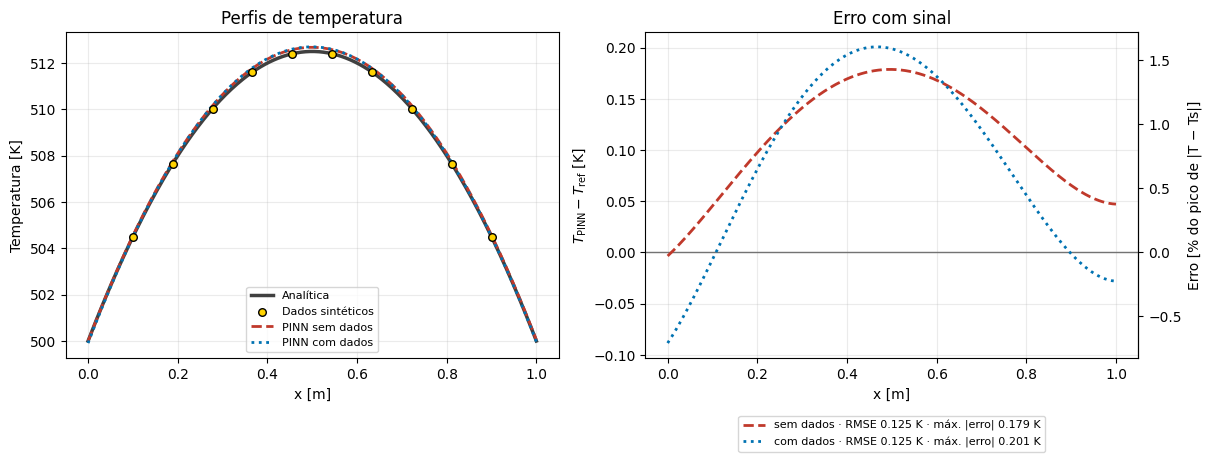

In [13]:
x = x_eval.ravel()
T_exata = T_ref_normalizada.ravel()
pico_excesso = np.max(np.abs(T_exata - Ts))

fig, (ax_T, ax_erro) = plt.subplots(
    1, 2, figsize=(12, 4.5), sharex=True, constrained_layout=True
)

ax_T.plot(x, T_exata, color="0.25", lw=2.5, label="Analítica")
ax_T.scatter(
    x_obs.ravel(), T_obs.ravel(), color="#FFD300", edgecolor="black",
    s=30, zorder=4, label="Dados sintéticos",
)
ax_erro.axhline(0, color="0.45", lw=1)

for nome, cor, estilo in [
    ("sem dados", "#C0392B", "--"),
    ("com dados", "#0072B2", ":"),
]:
    T_pred = resultados_norm[nome]["T_pred"].ravel()
    erro = T_pred - T_exata
    rmse = np.sqrt(np.mean(erro**2))
    erro_max = np.max(np.abs(erro))

    ax_T.plot(x, T_pred, color=cor, ls=estilo, lw=2, label=f"PINN {nome}")
    ax_erro.plot(
        x, erro, color=cor, ls=estilo, lw=2,
        label=f"{nome} · RMSE {rmse:.3f} K · máx. |erro| {erro_max:.3f} K",
    )

ax_T.set(title="Perfis de temperatura", ylabel="Temperatura [K]")
ax_erro.set(title="Erro com sinal", ylabel=r"$T_{\mathrm{PINN}} - T_{\mathrm{ref}}$ [K]")

if pico_excesso > 0:
    eixo_pct = ax_erro.secondary_yaxis(
        "right",
        functions=(
            lambda e: 100 * e / pico_excesso,
            lambda p: p * pico_excesso / 100,
        ),
    )
    eixo_pct.set_ylabel("Erro [% do pico de |T − Ts|]")

for ax in (ax_T, ax_erro):
    ax.set_xlabel("x [m]")
    ax.grid(alpha=0.25)

ax_T.legend(loc="lower center", fontsize=8)
ax_erro.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), fontsize=8)
plt.show()

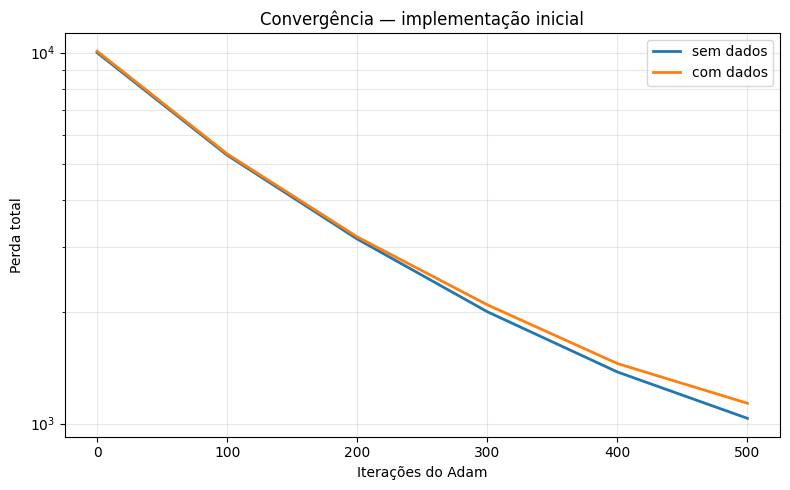

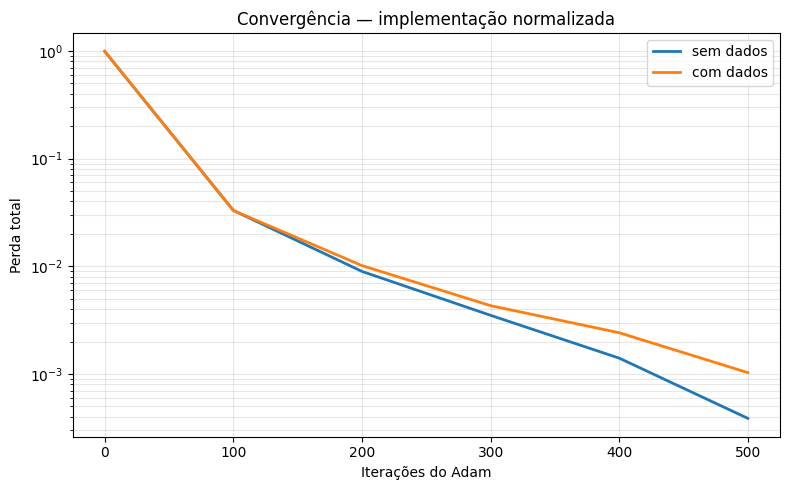

In [14]:
def plotar_perdas(resultados, titulo):
    fig, ax = plt.subplots(figsize=(8, 5))

    for nome, resultado in resultados.items():
        steps = np.asarray(resultado["losshistory"].steps)
        losses = np.asarray(resultado["losshistory"].loss_train, dtype=float)
        ax.semilogy(steps, np.sum(losses, axis=1), linewidth=2, label=nome)

    ax.set_title(titulo)
    ax.set_xlabel("Iterações do Adam")
    ax.set_ylabel("Perda total")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


plotar_perdas(resultados_raw, "Convergência — implementação inicial")
plotar_perdas(resultados_norm, "Convergência — implementação normalizada")

## **7. Conclusões**

- Na implementação inicial, a rede aproxima $u=T-T_s$, e não $T$. Comparar $u$ diretamente com $T$ produz um erro artificial da ordem de $T_s$.
- A conversão $T=T_s+u$ corrige a comparação de variáveis, mas ainda não controla a escala numérica da saída.
- Na implementação normalizada, a rede trabalha com $\xi$ e $\theta$, que permanecem em escalas mais adequadas ao treinamento.
- A solução normalizada não modifica a física do problema; ela apenas muda a forma como o problema é apresentado ao otimizador.
- Ao aumentar $k$ mantendo $\dot q$ fixo, a variação física de temperatura diminui. Esse efeito deve aparecer na solução, mas não deve causar uma perda de escala desnecessária no treinamento.

Para problemas inversos, há uma observação importante: se $k$ for justamente o parâmetro desconhecido, não se deve esconder $k$ completamente dentro da escala usada para normalizar o problema. Nesse caso, é melhor definir cuidadosamente uma escala de referência conhecida e manter o parâmetro desconhecido explicitamente no resíduo da PDE.